# 08 — Brain states × mapas de referência

Interpreta uma definição de cluster (um conjunto de brain states) em termos neuroanatômicos: a ativação média de cada estado no córtex e no subcórtex, e a correlação com mapas **moleculares** (PET, neuromaps), **comportamentais** (taxonomia BrainMap, perfis do Neurosynth calculados com o decodificador BrainMap do NiMARE nas parcelas do próprio atlas) e **canônicos** (Yeo 7 e as nossas 14 redes).

Duas etapas, dois módulos do pacote:

1. `fmri_decomposition.unsupervised_model.contextualization.correlations.compute(...)` → **tabelas** (`state_means.csv`, `correlations.csv`, `provenance.json`) em `outputs/modelling/version=<v>/unsupervised_model/contextualization/<estados>/<atlas>/`
2. `fmri_decomposition.figures.states.draw(...)` → **figuras** a partir dessas tabelas (visão geral + um card por estado)

Mapas de referência (~285 MB): ficam em `$FMRIDECOMP_REFMAPS`, senão em `<repo>/reference_atlases/` (no `.gitignore`). Para baixar: `fmri_decomposition/unsupervised_model/contextualization/fetch_reference_maps.sh`. Detalhes e limitações: `fmri_decomposition/unsupervised_model/contextualization/README.md`.

In [1]:
import sys
from pathlib import Path

# THE PACKAGE, which is not pip-installed inside the analysis image. A Jupyter
# kernel starts with sys.path[0] = the notebook's own directory, so without
# this `import fmri_decomposition` fails from notebooks/.
#
# The REPO ROOT and nothing else. `notebooks/` used to be on this list too,
# back when the table and figure modules lived beside the .ipynb files; that
# part is gone and must not come back -- a directory on sys.path can shadow a
# real package, which is how an ImportError turns into the wrong module.
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

# every figure of a "# Plot N.k" / "# Figure N" cell is written to notebooks/figures/04/ (N_k.png), overwritten each run
from fmri_decomposition.figures import autosave
autosave.enable(REPO / "notebooks" / "figures" / "04")
from IPython.display import Image, display

from fmri_decomposition.unsupervised_model.contextualization import correlations as sc
from fmri_decomposition.figures import states as sf

autosave: figures of '# Plot N.k' / '# Figure N' cells -> /project/6008063/tamires/DecomposingfMRI/notebooks/figures/04


## Parâmetros

**Definição de cluster** — `STATES`:
- `"simulate"`: seis estados simulados com resposta conhecida (para testar);
- uma coluna de estados do stage 4b, ex. `"HMM2_pca14_10"` (precisa de `OUTPUT_ROOT` e `WINDOW_S`);
- ou o caminho de um CSV escrito por `fmri-decomp state-means --csv`.

**Atlas** — `ATLASES`: onde os estados foram ajustados (`harvardoxford`, `networks_nodes`, `networks`, `yeo7`). Uma coluna de estados existe num atlas só. `LABELS_ATLAS`: o atlas cujo modelo definiu `STATES` — os rótulos vêm dele e a ativação de `ATLASES`, para desenhar e testar os estados de um modelo de atlas grosseiro (yeo7, 7 regiões, sem nulo espacial) nas 111 regiões do harvardoxford. Os frames são casados pelo tempo do estímulo, o mesmo em todos os atlas. O resultado vai para uma pasta própria (`..._labels-yeo7`).

**O que mostrar** — `FAMILIES` (painéis não comportamentais) e `TAXONOMY`: `"brainmap"` (categorias do BrainMap, Fox et al. 2005, traduzidas em termos do Neurosynth) ou `"beam2021"` (6 domínios data-driven de Beam et al. 2021: Memory, Reward, Cognition, Vision, Manipulation, Language). `BN_LEVELS`: profundidade — `"domain"` (os domínios), `"subcategory"` (BrainMap: ex. Vision · Motion; Beam: os termos de cada domínio), ou os dois.

**Estatística** — `N_NULLS` substitutos por mapa (`NULL="moran"`, segundos; `"burt"`, brainsmash, horas). Atlas com < 30 parcelas (`networks`, `yeo7`) ficam sem p-valor.

**Figura** — uma linha por estado: o cérebro em 2 × 3 (lateral E · lateral D · axial / medial E · medial D · coronal) e, ao lado, um gráfico de barras por família em `PANELS` (as `TOP` maiores |r|; categorias "Other" do BrainMap ficam de fora). As barras são a média de r entre sujeitos **± desvio padrão entre sujeitos** quando os estados vêm de uma coluna de estados ou da simulação (cada sujeito tem o seu mapa de estado); com um CSV de `state-means` só existe o mapa do grupo e as barras saem sem erro.

In [2]:
STATES      = "ThresholdCluster_umap3_8"        # o conjunto do manuscrito | "simulate" | "path/to/state_means.csv"
WINDOW_S    = -1                    # 30-s dFC (manuscrito); -1 = per-TR (activation)
COHORTS     = "train"               # "train" = só as coortes de treino do decompose | lista | None = todas
OUTPUT_ROOT = None                  # None = $FMRIDECOMP_OUTPUTS ou o output_root dos config/*.yaml

ATLASES     = ["harvardoxford"]     # + "networks_nodes", "networks", "yeo7": the parcels the maps are drawn and tested on
LABELS_ATLAS = "yeo7"              # the atlas whose model defined STATES (its labels are read); None = the same as ATLASES
                                   # e.g. the yeo7 model's states on harvardoxford's 111 parcels, where the spatial null can run
FAMILIES    = ["molecular", "yeo7", "networks14"]
BN_LEVELS   = ["domain", "subcategory"]     # profundidade da taxonomia comportamental
BEHAVIOURAL = "neurosynth_zreverse"   # inferência reversa do decodificador BrainMap do NiMARE (padrão) | "neurosynth_lancaster_reverse" | "neurosynth_lancaster_weighted" | "neurosynth_lancaster" | "neurosynth_lancaster_studies" | "brainmap" / "brainmap_reverse" (base BrainMap via Mango) | "brainmap_all" | "neurosynth" (zForward) | None = simulado
TAXONOMY    = "brainmap"            # "brainmap" (Fox 2005, com sinônimos) | "brainmap_pure" (só o nome da categoria, sem sinônimos) | "beam2021" (Beam et al. 2021)

PANELS      = ["yeo7", "behavioural"]   # gráficos ao lado de cada cérebro, nessa ordem
TOP         = 7                         # barras por gráfico (Yeo 7 mostra sempre as 7)
SPLIT       = (4, 3)              # bar panels but Yeo 7: the 4 most positive + 3 most negative r; None = the TOP largest |r|
POSITIVE_ONLY = ["behavioural"]          # gráficos só com r positivo; [] = positivos e negativos

N_NULLS     = 10_000
NULL        = "moran"
RESULTS     = None       # None = <outputs>/modelling/version=<v>/
                         #        unsupervised_model/contextualization/

## Nomes dos estados

Um nome por estado (as chaves são o índice do estado: 0 = S0, o "state 0" das figuras). A célula grava os nomes num arquivo do conjunto de estados (`state_names`), que os notebooks 05, 07 e 08 leem para escrever os nomes nas figuras. `STATE_LABELS` escolhe como as figuras deste notebook escrevem o estado: `"number"`, `"name"` ou `"both"`; os outros notebooks têm o mesmo parâmetro na sua célula de configuração.


In [3]:
STATE_NAMES = {
    0: "Social Cognition",
    1: "Language & Music",
    2: "Cognitive Attention",
    3: "Action Execution",
    4: "Reasoning",
    5: "Emotion",
    6: "Vision",
    7: "Soma Cognition",
}
STATE_LABELS = "name"     # "number" (S3) | "name" | "both" (S3 · name), for this notebook's figures

from fmri_decomposition.figures import state_names as sn
from fmri_decomposition.io import default_output_root
_root = OUTPUT_ROOT or default_output_root()
_model_atlas = LABELS_ATLAS or ATLASES[0]          # the names belong to the model's state set
print("written:", sn.save(STATE_NAMES, _root, _model_atlas, WINDOW_S, STATES))
sn.use_for(_root, _model_atlas, WINDOW_S, STATES, mode=STATE_LABELS)


written: /project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/state_names/atlas=yeo7/window_s=-1/states=ThresholdCluster_umap3_8.json
state labels: name · S0 Social Cognition, S1 Language & Music, S2 Cognitive Attention, S3 Action Execution, S4 Reasoning, S5 Emotion, S6 Vision, S7 Soma Cognition


{0: 'Social Cognition',
 1: 'Language & Music',
 2: 'Cognitive Attention',
 3: 'Action Execution',
 4: 'Reasoning',
 5: 'Emotion',
 6: 'Vision',
 7: 'Soma Cognition'}

## 1. Tabelas de correlação

In [4]:
dirs = sc.compute(
    STATES, ATLASES,
    families=FAMILIES + [sc.BN_LEVELS[b] for b in BN_LEVELS],
    out=RESULTS, output_root=OUTPUT_ROOT, window_s=WINDOW_S, cohorts=COHORTS, labels_atlas=LABELS_ATLAS,
    behavioural_csv=BEHAVIOURAL, n_nulls=N_NULLS, null=NULL, taxonomy=TAXONOMY,
)
run_dir = next(iter(dirs.values())).parent
run_dir

/project/6008063/tamires/DecomposingfMRI/fmri_decomposition/unsupervised_model/state_means.py:66: UserWarning: decompose_atlas-yeo7_window--1.joblib: the UMAP's pynndescent index was pickled with another pynndescent version and is loaded inert (scaler and PCA are fine; do not call umap.transform on this object).
  return loader(path)


[harvardoxford] COHORTS='train' -> ['ds002837', 'cneuromod']
[harvardoxford] ThresholdCluster_umap3_8: 8 states, activation from 91 subjects (frames)
[harvardoxford] molecular: 19 maps, q<.05: 0
[harvardoxford] behavioural_domain: 5 maps, q<.05: 4
[harvardoxford] behavioural: 41 maps, q<.05: 67
[harvardoxford] yeo7: 7 maps, q<.05: 15
[harvardoxford] networks14: 14 maps, q<.05: 3
[harvardoxford] 111 parcels (fmri_decomposition.get_atlas) -> /project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/contextualization/ThresholdCluster_umap3_8_window--1_labels-yeo7_zreverse/harvardoxford


PosixPath('/project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/contextualization/ThresholdCluster_umap3_8_window--1_labels-yeo7_zreverse')

In [5]:
import pandas as pd
cor = pd.concat({a: pd.read_csv(d / "correlations.csv") for a, d in dirs.items()}, names=["atlas"])
cor.sort_values("p_null").groupby(["atlas", "family"]).head(3)

state state_name              family  \
atlas                                                     
harvardoxford 478      6    state 6         behavioural   
              477      6    state 6         behavioural   
              480      7    state 7         behavioural   
              152      0    state 0  behavioural_domain   
              156      0    state 0  behavioural_domain   
              575      7    state 7                yeo7   
              568      6    state 6                yeo7   
              544      3    state 3                yeo7   
              191      7    state 7  behavioural_domain   
              600      1    state 1          networks14   
              656      5    state 5          networks14   
              670      6    state 6          networks14   
              9        0    state 0           molecular   
              142      7    state 7           molecular   
              66       3    state 3           molecular   

                                       map         r    p_null     q_fdr  \
atlas                                                                      
harvardoxford 478        Perception.Vision  0.829172  0.000100  0.001261   
              477  Perception.Vision.Shape  0.807466  0.000100  0.001261   
              480         Action.Execution  0.654341  0.000100  0.001261   
              152                   Action -0.559340  0.000100  0.001333   
              156               Perception -0.764890  0.000100  0.001333   
              575                  Default -0.612969  0.000100  0.000800   
              568                  Default -0.566989  0.000100  0.000800   
              544        Ventral Attention  0.664508  0.000100  0.000800   
              191               Perception  0.684416  0.000100  0.001333   
              600                      ToM  0.347826  0.000300  0.033597   
              656                      ToM  0.338203  0.001000  0.041063   
              670                      ToM -0.316852  0.001100  0.041063   
              9                        NET -0.428770  0.003400  0.311569   
              142                      NET  0.431153  0.004100  0.311569   
              66                       NET  0.539892  0.023098  0.854155   

                   map_simulated  
atlas                             
harvardoxford 478          False  
              477          False  
              480          False  
              152          False  
              156          False  
              575          False  
              568          False  
              544          False  
              191          False  
              600          False  
              656          False  
              670          False  
              9            False  
              142          False  
              66           False

## 2. Figuras

#### Plot 4.0 — state maps and their profiles (Figure 2)


[harvardoxford] figures -> /project/6008063/tamires/DecomposingfMRI/outputs/modelling/version=v0/unsupervised_model/contextualization/ThresholdCluster_umap3_8_window--1_labels-yeo7_zreverse/harvardoxford


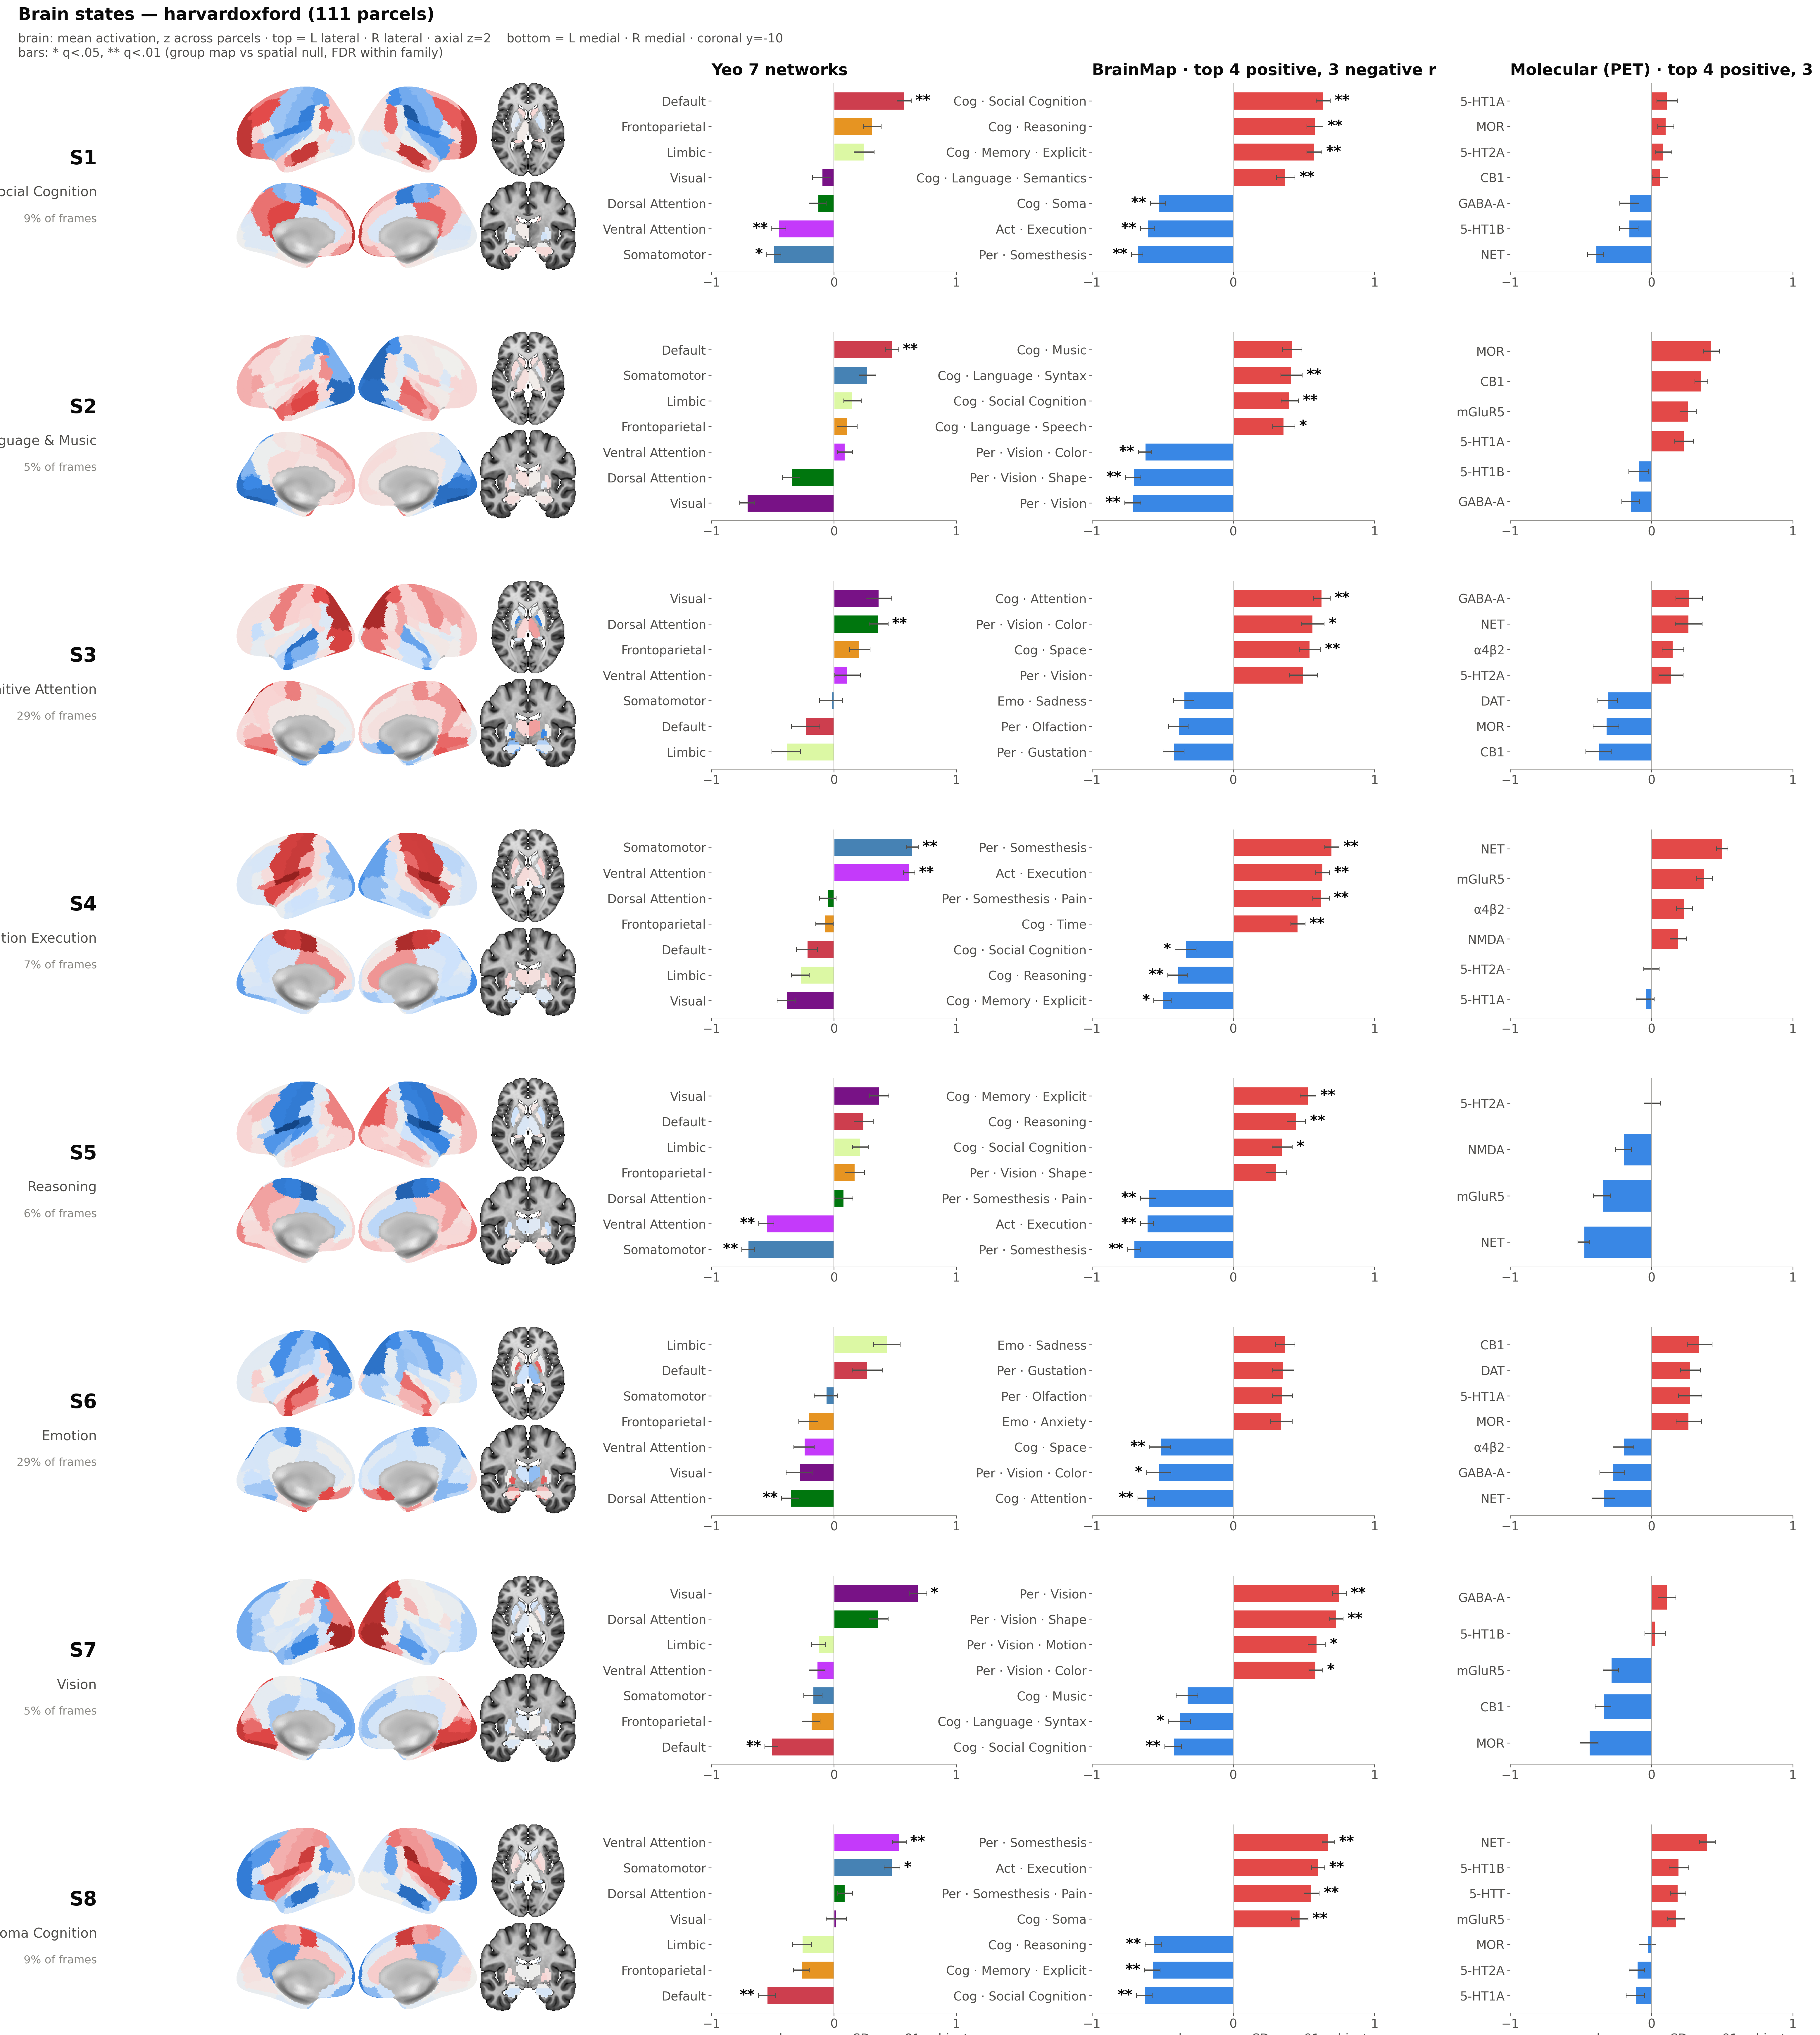

In [6]:
# Plot 4.0
SAVE_AS = None    # None = "4_0" -> notebooks/figures/04/4_0.png; to keep another version: SAVE_AS = "4_0_version2"
PANELS = ["yeo7", "behavioural", "molecular"] # "molecular","networks14"
paths = sf.draw(run_dir, atlases=ATLASES, families=FAMILIES, bn_levels=BN_LEVELS,
                panels=PANELS, top=TOP, split=SPLIT)#, positive_only=POSITIVE_ONLY)
for p in paths:
    display(Image(filename=str(p)))

## 3. Matriz entre mapas de referência

Correlação espacial, entre as parcelas do atlas escolhido, entre cada mapa de uma família (linhas) e cada mapa de outra (colunas) — por padrão as 7 redes de Yeo × as 38 subcategorias do BrainMap (perfis do Neurosynth, zForward do decodificador BrainMap do NiMARE, contados nas parcelas do atlas; sem as "Other"). Não depende dos estados. Asteriscos: `*` q<.05, `**` q<.01, contra mapas substitutos que preservam a autocorrelação espacial, FDR sobre a matriz inteira. Famílias: `molecular`, `behavioural`, `behavioural_domain`, `yeo7`, `networks14`. Famílias: `molecular`, `behavioural`, `behavioural_domain`, `yeo7`, `networks14` — e `states`: os brain states da seção 1 (o `state_means.csv` do atlas escolhido), cada estado contra cada mapa da outra família, com o mesmo nulo espacial.


#### Plot 4.1 — reference matrix, Yeo 7 × behavioural


In [ ]:
# Plot 4.1
SAVE_AS = None    # None = "4_1" -> notebooks/figures/04/4_1.png; to keep another version: SAVE_AS = "4_1_version2"
MATRIX_ATLAS = "harvardoxford"     # "harvardoxford" | "networks_nodes" | "networks" | "yeo7"
MATRIX_ROWS  = "states"            # "states" = the brain states of section 1 | "yeo7" | "molecular" | ...
MATRIX_COLS  = "behavioural"
MATRIX_CLUSTER = "both"       # hierarchical clustering + dendrogram: None | "rows" | "cols" | "both"
MATRIX_CORTICAL_ONLY = None    # None = só parcelas corticais quando Yeo 7 é um dos lados (Yeo é cortical) | True | False

png = sf.reference_matrix(MATRIX_ATLAS, MATRIX_ROWS, MATRIX_COLS, taxonomy=TAXONOMY,
                          behavioural_csv=BEHAVIOURAL, n_nulls=N_NULLS, null=NULL,
                          cortical_only=MATRIX_CORTICAL_ONLY, cluster=MATRIX_CLUSTER,
                          states_table=dirs[MATRIX_ATLAS] / "state_means.csv" if MATRIX_ATLAS in dirs else None)
display(Image(filename=str(png)))

In [ ]:
# Plot 4.1
SAVE_AS = None    # None = "4_1_b" -> notebooks/figures/04/4_1_b.png; to keep another version: SAVE_AS = "4_1_b_version2"
MATRIX_ATLAS = "harvardoxford"     # "harvardoxford" | "networks_nodes" | "networks" | "yeo7"
MATRIX_ROWS  = "behavioural"
MATRIX_COLS  = "behavioural"
MATRIX_CLUSTER = "both"       # hierarchical clustering + dendrogram: None | "rows" | "cols" | "both"
MATRIX_CORTICAL_ONLY = None    # None = só parcelas corticais quando Yeo 7 é um dos lados (Yeo é cortical) | True | False

png = sf.reference_matrix(MATRIX_ATLAS, MATRIX_ROWS, MATRIX_COLS, taxonomy=TAXONOMY,
                          behavioural_csv=BEHAVIOURAL, n_nulls=N_NULLS, null=NULL,
                          cortical_only=MATRIX_CORTICAL_ONLY, cluster=MATRIX_CLUSTER,
                          states_table=dirs[MATRIX_ATLAS] / "state_means.csv" if MATRIX_ATLAS in dirs else None)
display(Image(filename=str(png)))

## 4. Outras visualizações (opcional)

Descomente para gerar. Usam **todas as famílias** de `FAMILIES` + `BN_LEVELS` (moleculares, comportamentais, Yeo 7, nossas 14 redes), não só `PANELS`.

In [ ]:
# Cards: um por estado, com barras de todas as famílias
sf.draw(run_dir, atlases=ATLASES, families=FAMILIES, bn_levels=BN_LEVELS, cards=True)
for atlas in ATLASES:
    for card in sorted(dirs[atlas].glob("state_card_S*.png"),
                       key=lambda p: int(p.stem.rsplit("S", 1)[1])):
        print(atlas, card.stem)
        display(Image(filename=str(card)))

## 5. Nomes dos estados

Regra (Métodos): **rede de Yeo dominante + domínio BrainMap dominante do polo positivo** — para cada estado, a rede com maior r positivo entre as 7 de Yeo e o domínio (Action, Cognition, Emotion, Interoception, Perception) com maior r positivo. Marcamos com `*` quando a associação passa q < .05 contra o nulo espacial. A tabela é uma proposta: confira com as figuras antes de usar os nomes no texto.


In [ ]:
NAME_ATLAS = ATLASES[0]
c = pd.read_csv(dirs[NAME_ATLAS] / "correlations.csv")

def top_positive(fam):
    t = c[(c["family"] == fam) & (c["r"] > 0)].sort_values("r", ascending=False)
    return t.groupby("state").head(1).set_index("state")

net, dom = top_positive("yeo7"), top_positive("behavioural_domain")
names = pd.DataFrame(index=sorted(c["state"].unique()))
names["network"] = net["map"]
names["r_network"] = net["r"].round(2)
names["q_network"] = net["q_fdr"]
names["domain"] = dom["map"]
names["r_domain"] = dom["r"].round(2)
names["q_domain"] = dom["q_fdr"]
names["proposed_name"] = [
    f"{n}{'*' if pd.notna(qn) and qn < .05 else ''}–{d}{'*' if pd.notna(qd) and qd < .05 else ''}"
    for n, d, qn, qd in zip(names["network"], names["domain"], names["q_network"], names["q_domain"])]
names


In [ ]:
import pandas as pd
sm = pd.read_csv(dirs["harvardoxford"] / "state_means.csv", index_col="state")
regs = [c for c in sm.columns if c not in ("n_rows", "share", "name")]

STATE = 7                                   # índice do estado (ver a nota abaixo)
row = sm.loc[STATE, regs].sort_values(ascending=False)
print("mais ativas, cérebro todo:\n", row.head(5).round(2))
print("\nmais ativas, hemisfério direito:\n", row[[r for r in row.index if r.startswith("Right")]].head(5).round(2))

In [ ]:
# BrainMap categories of ONE region, by NiMARE's BrainMap decoder on Neurosynth (the Figure 2 table)
import pandas as pd
from fmri_decomposition.io import require_reference_maps
from fmri_decomposition.unsupervised_model.contextualization import refmaps as rm

REGION = "Right_Supramarginal_Gyrus_anterior_division"
ATLAS  = "harvardoxford"
STAT   = BEHAVIOURAL.replace("neurosynth_", "") if BEHAVIOURAL.startswith("neurosynth_") else "zreverse"

data = require_reference_maps()
ref = rm.reference_grid(data)
spec, _ = rm.state_atlas(ATLAS, data)
parc = rm.Parcellator.build(spec, ref)
tab = rm.neurosynth_behavioural_table(data, ref, TAXONOMY, labels=parc.label_volume(),
                                      key=ATLAS, statistic=STAT)          # cached: read, not recomputed
tab["region"] = [parc.columns[int(p) - 1] for p in tab["parcel"]]
row = tab.set_index("region").loc[REGION].drop([c for c in ("parcel", "bn_index") if c in tab], errors="ignore")
row = pd.to_numeric(row, errors="coerce").dropna()
row = row[~row.index.str.endswith(".Other")].sort_values(ascending=False)
print(f"{REGION} · {STAT} · {TAXONOMY}")
display(row.head(10).round(2).to_frame("z"))